# Detecção de Objetos por Template Matching
**Computação Visual — Universidade Presbiteriana Mackenzie**  
**Opção 2: Tutorial teórico e prático**

| Integrante | Responsabilidade | RA |
|---|---|---|
| Alexandre Eiji Tomimura Carvalho | Fundamentação teórica, algoritmos e exemplos ilustrativos | 10371680 |
| João Pedro Pioltini de Oliveira | Implementação prática em Python e OpenCV | 10425643 |
| Matheus Veiga Bacetic Joaquim | Experimentos, análise, aplicações, limitações e conclusão | 10425638 |

Este é o ponto de entrada do tutorial. Leia a teoria, execute os exemplos na ordem e prossiga para o [notebook de experimentos de Matheus](Experimentos_Template_Matching_Matheus.ipynb). A implementação de João permanece em [template_matching.py](template_matching.py) e é importada nos exemplos, sem duplicação do algoritmo.

**Percurso:** 1. Introdução → 2. Fundamentação teórica → 3. Implementação prática → 4. Experimentos e análise → 5. Limitações e aplicações → 6. Conclusão → 7. Referências.

**Preparação:** siga o [README](README.md), abra este notebook na raiz do repositório e selecione o kernel do ambiente onde instalou as dependências. Execute do início ao fim. As imagens são locais; nenhuma célula baixa dados ou instala pacotes.

# 1. Introdução
Localizar um padrão visual conhecido é uma tarefa recorrente em inspeção de peças, automação de interfaces e análise de imagens. Neste tutorial, investigamos como um pequeno recorte pode indicar a posição de uma região semelhante em uma imagem maior.

O objetivo é compreender o cálculo da correspondência, interpretar seu mapa de pontuações e conectar esse raciocínio ao programa do projeto. A fotografia `image2.jpg` e o recorte `exemplo/template_hamster.png` permitem estudar um caso concreto. O par `exemplo/imagem.png` e `exemplo/template.png` oferece uma segunda entrada para a linha de comando.

Trabalhamos com busca por translação, template de tamanho fixo e comparação em escala de cinza. Não há treinamento de um classificador. Mudanças de tamanho ou orientação exigem estratégias adicionais, examinadas nos experimentos.

# 2. Fundamentação Teórica — Template Matching
## 2.1. O que é Template Matching?
Imagine percorrer uma fotografia com um recorte em mãos, tentando encontrar onde ele se encaixa melhor. O **Template Matching** formaliza essa comparação: uma imagem de entrada contém a cena de busca, e o **template** é uma pequena imagem de referência, geralmente um recorte retangular do padrão procurado. O algoritmo atribui uma pontuação a cada encaixe possível.

No projeto, `image2.jpg` contém a cena e `exemplo/template_hamster.png` fornece a aparência que será procurada. O resultado é a posição de uma região visualmente semelhante ao recorte. Isso não significa reconhecer semanticamente a categoria “hamster”: outro hamster, com pose ou tamanho diferentes, pode não corresponder ao template. Uma textura parecida também pode produzir uma resposta elevada.

A técnica é útil para localizar ícones em capturas de tela, conferir o posicionamento de componentes e procurar marcas em imagens de inspeção. Sua aplicação pressupõe que a aparência esperada seja suficientemente estável e discriminativa. A existência de uma melhor posição não comprova a presença do objeto: mesmo uma cena sem o padrão tem um mínimo e um máximo de pontuação.

## 2.2. Funcionamento geral do algoritmo
A **janela deslizante** (*sliding window*) é uma região com a mesma largura e altura do template, posicionada sucessivamente sobre a imagem. Com passo unitário, deslocamos sua origem um pixel por vez, considerando somente posições em que todo o template cabe na imagem.

1. Recebemos a imagem principal, que delimita a área de busca.
2. Recebemos o template e verificamos suas dimensões.
3. Posicionamos a janela na origem e percorremos as posições válidas.
4. Comparamos os pixels do template com os pixels da janela atual.
5. Calculamos uma pontuação segundo o método escolhido.
6. Guardamos cada pontuação em uma matriz de resultados.
7. Selecionamos o mínimo ou o máximo dessa matriz, conforme o método.
8. Usamos a posição selecionada e as dimensões do template para marcar a região.

Por exemplo, uma imagem de largura 5 e altura 4 admite um template de largura 2 e altura 2 nas posições `(0,0)`, `(1,0)`, `(2,0)`, `(3,0)`, depois `(0,1)` até `(3,1)` e, por fim, `(0,2)` até `(3,2)`. São 12 comparações. A janela se move; os valores do template permanecem fixos. Essa ordem é didática: o OpenCV pode otimizar os cálculos sem executar literalmente esse laço em Python.

## 2.3. Representação matemática
Usamos coordenadas com origem no canto superior esquerdo: $x$ cresce para a direita e $y$ para baixo.

| Símbolo | Significado |
|---|---|
| $I$ | Imagem principal de largura $W$ e altura $H$ |
| $T$ | Template de largura $w$ e altura $h$ |
| $R$ | Matriz de pontuações de correspondência |
| $(x,y)$ | Canto superior esquerdo da janela na imagem |
| $(i,j)$ | Coordenada local do pixel no template, com $0\leq i<w$ e $0\leq j<h$ |

A janela na posição $(x,y)$ é $P_{x,y}(i,j)=I(x+i,y+j)$. As posições válidas satisfazem $0\leq x\leq W-w$ e $0\leq y\leq H-h$. Assim, com passo unitário e sem preenchimento (*padding*), o mapa tem dimensões **largura × altura**:

$$
(W-w+1)\times(H-h+1).
$$

No exemplo anterior, $(5-2+1)\times(4-2+1)=4\times3$: quatro colunas, três linhas e 12 pontuações. Se a imagem tivesse $640\times480$ pixels e o template $64\times48$, o mapa teria $577\times433$ posições.

**Atenção à convenção:** a notação matemática $R(x,y)$ usa coordenadas; arrays NumPy são indexados por linha e coluna, como `R[y, x]`. Portanto, `R.shape` é `(H-h+1, W-w+1)`. A localização representa o canto da janela, e não o centro do objeto. As fórmulas a seguir descrevem imagens de um canal, como as imagens em cinza usadas pelo script.

## 2.4. Matriz de correspondência
Cada elemento `R[y, x]` sintetiza a comparação entre o template inteiro e uma janela da imagem. O mapa é menor que a imagem porque não são avaliadas posições onde a janela ultrapassaria as bordas.

Um **mapa de similaridade** permite enxergar regiões candidatas, mas “mapa de correspondência” é um termo mais geral: nos métodos de diferença quadrática, o valor mede erro, de modo que regiões escuras de um heatmap crescente podem ser as melhores. Nos métodos de correlação, procuramos os máximos. A barra de cores deve indicar a pontuação e sua direção de interpretação.

O heatmap não é uma distribuição de probabilidades. Um pico pode surgir em texturas repetidas, e posições próximas podem responder de forma parecida porque suas janelas compartilham muitos pixels. O projeto já produz esse mapa em `executar_template_matching()` e o apresenta em `visualizar_resultados()`. Na seção 2.7, vamos reutilizar o mapa calculado pela mesma função e marcar sua posição vencedora.

## 2.5. Métodos de comparação
As expressões abaixo seguem as definições do [OpenCV para os modos de Template Matching](https://docs.opencv.org/4.x/df/dfb/group__imgproc__object.html). Todas as somas percorrem $i=0,\ldots,w-1$ e $j=0,\ldots,h-1$, sem máscara.

### A. Soma dos quadrados das diferenças (SSD / SQDIFF)

$$
R_{\mathrm{SQDIFF}}(x,y)=\sum_{i,j}\left(T(i,j)-I(x+i,y+j)\right)^2.
$$

Subtraímos pixels correspondentes e elevamos as diferenças ao quadrado. Dessa forma, diferenças positivas e negativas não se cancelam e erros maiores pesam mais. **Menor é melhor**: uma cópia exata tem erro ideal zero, sujeito a pequenas diferenças numéricas no cálculo. Mudanças de brilho podem aumentar o erro mesmo sem alterar a geometria do padrão.

### B. Correlação cruzada (CCORR)

$$
R_{\mathrm{CCORR}}(x,y)=\sum_{i,j}T(i,j)\,I(x+i,y+j).
$$

Multiplicamos intensidades correspondentes e somamos. Pixels intensos do template contribuem mais quando se alinham a pixels intensos da janela. **Maior é melhor segundo esse critério**, mas a versão bruta pode favorecer janelas muito claras ou com grande energia. Por isso, maximizar CCORR não garante o alinhamento semanticamente desejado nem equivale a minimizar SSD.

### C. Coeficiente de correlação (CCOEFF)
Definimos as médias do template e da janela:

$$
\bar T=\frac{1}{wh}\sum_{i,j}T(i,j),\qquad
\bar P_{x,y}=\frac{1}{wh}\sum_{i,j}I(x+i,y+j).
$$

Os valores centralizados são $T'(i,j)=T(i,j)-\bar T$ e $P'_{x,y}(i,j)=I(x+i,y+j)-\bar P_{x,y}$. Logo:

$$
R_{\mathrm{CCOEFF}}(x,y)=\sum_{i,j}T'(i,j)P'_{x,y}(i,j).
$$

Agora comparamos desvios em relação à média de cada região: partes relativamente claras e escuras devem se alinhar. **Maior é melhor**. Subtrair a média reduz o efeito de um deslocamento aditivo uniforme de brilho. Isso não oferece invariância geral à iluminação: sombras locais, saturação e transformações não lineares ainda alteram o padrão. A versão bruta também depende da amplitude do contraste.

### Versões normalizadas e interpretação das pontuações
Para SQDIFF e CCORR, o denominador é a média geométrica das energias das duas regiões:

$$
D(x,y)=\sqrt{\left(\sum_{i,j}T(i,j)^2\right)
                    \left(\sum_{i,j}P_{x,y}(i,j)^2\right)}.
$$

$$
R_{\mathrm{SQDIFF\_NORMED}}=\frac{R_{\mathrm{SQDIFF}}}{D},\qquad
R_{\mathrm{CCORR\_NORMED}}=\frac{R_{\mathrm{CCORR}}}{D}.
$$

Para CCOEFF, normalizamos pelas energias **após centralização**:

$$
R_{\mathrm{CCOEFF\_NORMED}}(x,y)=
\frac{\sum_{i,j}T'(i,j)P'_{x,y}(i,j)}
{\sqrt{\left(\sum_{i,j}T'(i,j)^2\right)
             \left(\sum_{i,j}P'_{x,y}(i,j)^2\right)}}.
$$

A normalização reduz a dependência da magnitude dos pixels e facilita definir limiares dentro de um método. Em condições ideais, CCOEFF normalizado preserva a resposta a mudanças de brilho e a ganhos positivos de contraste, desde que não haja recorte de intensidades nem variância nula. Nenhuma normalização resolve automaticamente mudanças de escala espacial, rotação ou oclusão.

Para entradas não negativas em cinza, CCORR normalizado fica teoricamente entre 0 e 1; com entradas assinadas, pode ser negativo. CCOEFF normalizado tem faixa teórica de −1 a 1 para variâncias não nulas: 1 indica alinhamento linear positivo, 0 indica ausência de correlação linear e −1 indica inversão. A razão de SSD normalizada é não negativa e **a fórmula isolada pode ultrapassar 1**; a implementação usual sem máscara do OpenCV satura respostas desse método em 1. Não trate essas faixas como equivalentes nem ignore casos degenerados, arredondamentos ou diferenças entre caminhos de implementação.

Se uma energia ou variância do denominador for zero, a expressão matemática fica indefinida. A função do projeto rejeita templates constantes em `TM_CCOEFF_NORMED`; regiões constantes da imagem também exigem cuidado na interpretação.

| Método | Princípio | Melhor correspondência |
|---|---|---|
| `cv2.TM_SQDIFF` | Diferença quadrática | Menor valor |
| `cv2.TM_SQDIFF_NORMED` | Diferença quadrática normalizada | Menor valor |
| `cv2.TM_CCORR` | Correlação cruzada | Maior valor |
| `cv2.TM_CCORR_NORMED` | Correlação cruzada normalizada | Maior valor |
| `cv2.TM_CCOEFF` | Correlação com valores centralizados | Maior valor |
| `cv2.TM_CCOEFF_NORMED` | Correlação centralizada normalizada | Maior valor |

Não compare diretamente pontuações brutas entre métodos: cada expressão tem escala e significado próprios. Mesmo dois resultados normalizados não são medidas intercambiáveis nem probabilidades de presença. Uma pontuação maior só melhora a correspondência nos critérios de maximização; para SQDIFF queremos o mínimo. A escolha depende das condições da cena e deve ser avaliada com exemplos positivos e negativos. Os experimentos de Matheus permitem observar efeitos de iluminação, escala, rotação e ruído para CCOEFF normalizado.

## 2.6. Identificação da melhor correspondência
`cv2.matchTemplate(imagem, template, metodo)` compara todas as janelas válidas e retorna o mapa de pontuações em ponto flutuante. No projeto, `executar_template_matching()` prepara entradas em cinza, verifica dimensões e converte os arrays para `float32` antes de chamar essa função.

`cv2.minMaxLoc(R)` retorna quatro informações:

| Retorno | Interpretação |
|---|---|
| `minVal` | Menor pontuação do mapa |
| `maxVal` | Maior pontuação do mapa |
| `minLoc` | Coordenada `(x, y)` do mínimo |
| `maxLoc` | Coordenada `(x, y)` do máximo |

`encontrar_melhor_correspondencia()` escolhe `minLoc` nos dois métodos SQDIFF e `maxLoc` nos outros quatro. Em caso de empates, uma única posição devolvida não resume todas as regiões igualmente boas.

Com a posição `(x, y)` e o tamanho `(w, h)`, os pixels da janela vão de `(x, y)` a `(x+w-1, y+h-1)`. A função `destacar_objeto()` usa esses cantos para desenhar um retângulo em uma cópia da imagem. NumPy acessa a mesma região por `imagem[y:y+h, x:x+w]`, pois o limite final da fatia é exclusivo.

**Localização e decisão são etapas distintas.** O programa de linha de comando só destaca a região se a pontuação satisfizer o limiar. O padrão é 0,8 para os métodos de correlação normalizada e 0,2 para SQDIFF normalizado; os métodos brutos exigem `--limiar` explícito. Esses valores são heurísticas e devem ser ajustados ao cenário. O exemplo didático abaixo sempre destaca a melhor posição para explicar a geometria; imprime também se ela atende ao limiar do método escolhido.

## 2.7. Exemplo visual do processo completo
**Imagem original → Template → Comparação → Mapa de resultados → Melhor posição → Objeto destacado**

Primeiro, um exemplo numérico pequeno torna a comparação verificável à mão. Depois, usamos a fotografia e o template existentes com as funções de João. Os gráficos ficam salvos nas saídas deste notebook e podem ser regenerados sem criar arquivos de imagem auxiliares.

In [1]:
%matplotlib inline
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from template_matching import (
    carregar_imagem, converter_cinza, executar_template_matching,
    encontrar_melhor_correspondencia, destacar_objeto, visualizar_resultados,
)

raiz = Path.cwd()
for caminho in ('image2.jpg', 'exemplo/template_hamster.png'):
    if not (raiz / caminho).is_file():
        raise FileNotFoundError(f'Abra o notebook na raiz do repositório: falta {caminho}')
plt.rcParams.update({'font.size': 10, 'figure.dpi': 100})

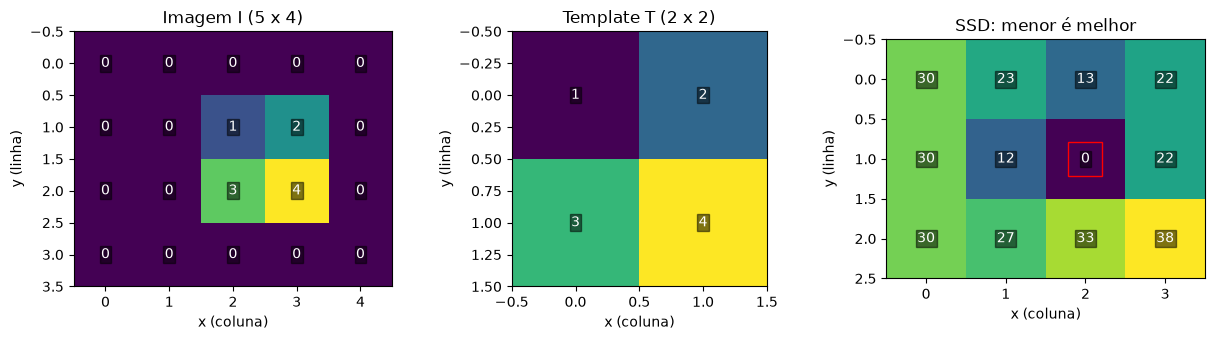

Janela (0, 0): soma dos erros quadráticos = 30
Janela (1, 1): soma dos erros quadráticos = 12
Janela (2, 1): soma dos erros quadráticos = 0


In [2]:
# Imagem 5 x 4 e template 2 x 2: a cópia exata começa em (2, 1).
I = np.array([[0, 0, 0, 0, 0],
              [0, 0, 1, 2, 0],
              [0, 0, 3, 4, 0],
              [0, 0, 0, 0, 0]], dtype=np.float32)
T = np.array([[1, 2], [3, 4]], dtype=np.float32)
R = executar_template_matching(I, T, cv2.TM_SQDIFF)
melhor = encontrar_melhor_correspondencia(R, cv2.TM_SQDIFF)
assert R.shape == (3, 4) and melhor == (2, 1)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for eixo, dados, titulo in zip(ax, (I, T, R),
                              ('Imagem I (5 x 4)', 'Template T (2 x 2)', 'SSD: menor é melhor')):
    im = eixo.imshow(dados, cmap='viridis')
    for (linha, coluna), valor in np.ndenumerate(dados):
        eixo.text(coluna, linha, f'{valor:.0f}', ha='center', va='center',
                  color='white', bbox=dict(facecolor='black', alpha=0.5, pad=1))
    eixo.set(title=titulo, xlabel='x (coluna)', ylabel='y (linha)')
ax[2].plot(*melhor, marker='s', markersize=24, fillstyle='none', color='red')
fig.tight_layout()
plt.show()
for x, y in ((0, 0), (1, 1), melhor):
    erro = np.sum((T - I[y:y+2, x:x+2]) ** 2)
    assert np.isclose(R[y, x], erro, atol=1e-4)
    print(f'Janela ({x}, {y}): soma dos erros quadráticos = {erro:.0f}')

Na primeira janela, os quatro pixels são zero: o erro é `1² + 2² + 3² + 4² = 30`. Na posição `(1,1)`, com janela `[[0,1],[0,3]]`, ele cai para 12. Em `(2,1)`, a janela é igual ao template e o erro é zero. Cada número no terceiro painel corresponde ao canto de uma janela no primeiro painel. O quadrado vermelho indica o mínimo, e não o maior valor do heatmap.

In [3]:
imagem = carregar_imagem(raiz / 'image2.jpg')
template = carregar_imagem(raiz / 'exemplo/template_hamster.png')
metodo = cv2.TM_CCOEFF_NORMED
mapa = executar_template_matching(imagem, template, metodo)
posicao = encontrar_melhor_correspondencia(mapa, metodo)
h, w = template.shape[:2]
H, W = imagem.shape[:2]
pontuacao = float(mapa[posicao[1], posicao[0]])
assert mapa.shape == (H-h+1, W-w+1)
assert np.isfinite(mapa).all()
print(f'Imagem: {W} x {H}; template: {w} x {h}; mapa: {mapa.shape} (linhas, colunas)')
print(f'Melhor canto: {posicao}; pontuação: {pontuacao:.6f}; atende a 0,8: {pontuacao >= 0.8}')

Imagem: 735 x 777; template: 215 x 215; mapa: (563, 521) (linhas, colunas)
Melhor canto: (375, 165); pontuação: 1.000000; atende a 0,8: True


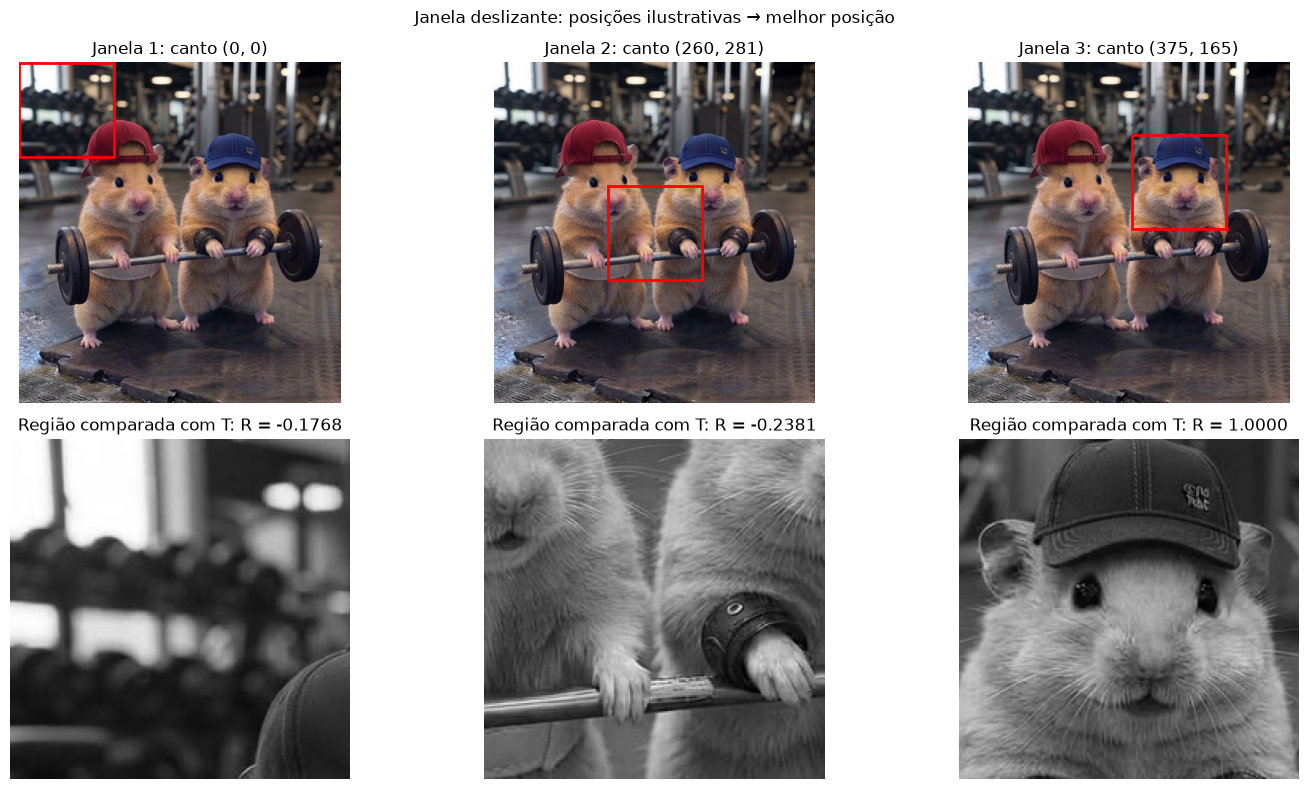

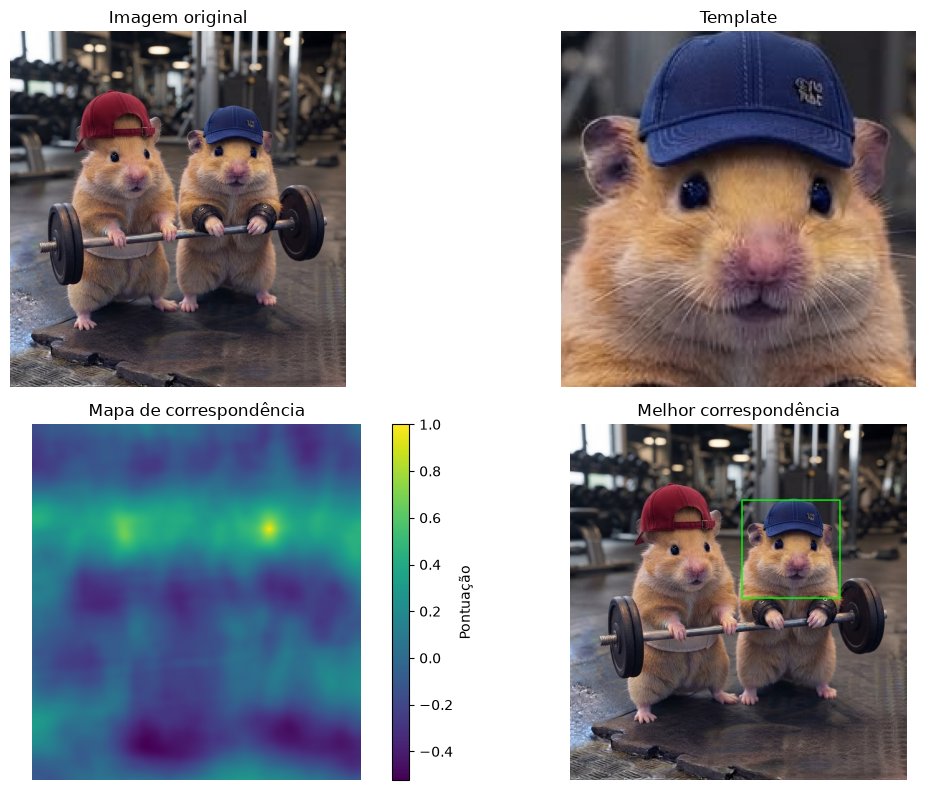

In [4]:
# Três posições ilustram o deslizamento; a última é a vencedora calculada.
posicoes = [(0, 0), ((W-w)//2, (H-h)//2), posicao]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for k, (x, y) in enumerate(posicoes):
    ax[0, k].imshow(cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB))
    ax[0, k].add_patch(Rectangle((x, y), w, h, fill=False,
                                 edgecolor='red', linewidth=2))
    ax[0, k].set_title(f'Janela {k+1}: canto ({x}, {y})')
    ax[1, k].imshow(converter_cinza(imagem)[y:y+h, x:x+w], cmap='gray', vmin=0, vmax=255)
    ax[1, k].set_title(f'Região comparada com T: R = {mapa[y, x]:.4f}')
for eixo in ax.flat:
    eixo.axis('off')
fig.suptitle('Janela deslizante: posições ilustrativas → melhor posição')
fig.tight_layout()
plt.show()

# Reutiliza a visualização original de João: original, template, mapa e destaque.
destaque = destacar_objeto(imagem, posicao, (w, h))
figura = visualizar_resultados(imagem, template, mapa, destaque)

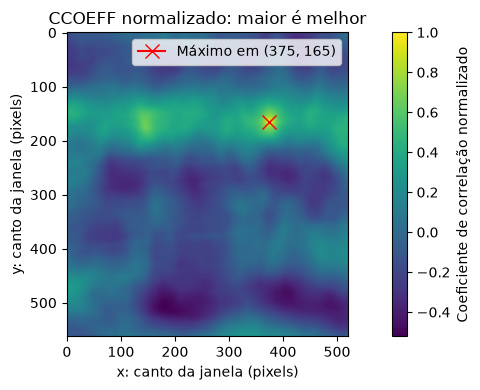

In [5]:
fig, eixo = plt.subplots(figsize=(9, 4))
exibicao = eixo.imshow(mapa, cmap='viridis')
eixo.plot(*posicao, marker='x', color='red', markersize=10, label=f'Máximo em {posicao}')
eixo.set(title='CCOEFF normalizado: maior é melhor',
         xlabel='x: canto da janela (pixels)', ylabel='y: canto da janela (pixels)')
eixo.legend()
fig.colorbar(exibicao, ax=eixo, label='Coeficiente de correlação normalizado')
fig.tight_layout()
plt.show()

O primeiro conjunto de painéis torna visível qual região é comparada em três posições; a busca real avalia todas as posições válidas. A visualização de João identifica a imagem original, o template, o mapa e a região destacada. No último heatmap, o marcador vermelho localiza o máximo em coordenadas de canto de janela.

A pontuação impressa é a do mapa usado para desenhar o resultado. Ela não é uma porcentagem de confiança. Como o template é um recorte da própria cena, este é um exemplo favorável: ele explica o mecanismo, mas não mede generalização para outras fotografias. Avaliar robustez exige os experimentos seguintes e imagens adicionais.

## 2.8. Relação com a implementação prática
O **OpenCV** fornece leitura, conversão de cores, comparação e desenho. `carregar_imagem()` usa `cv2.imread()` e informa falhas de leitura. As imagens coloridas são carregadas em BGR; a visualização com Matplotlib converte para RGB. `converter_cinza()` reduz cada pixel a uma intensidade, simplificando a comparação e descartando informação cromática. Isso pode tornar cores distintas menos discriminativas.

O **NumPy** representa imagens e mapas como arrays, permite consultar dimensões, selecionar janelas e calcular estatísticas. O script converte as entradas para `float32`, um tipo aceito por `matchTemplate()`. `minMaxLoc()` fornece extremos e localizações; a função de seleção respeita a direção de cada método. Matplotlib apresenta imagens e heatmaps, enquanto `destacar_objeto()` marca a região na imagem original.

Assim, o percurso conceitual corresponde diretamente às funções existentes: carregar → converter e comparar → selecionar → destacar → visualizar. Com essa base, a próxima seção apresenta como executar o programa de João e, depois, encaminha aos experimentos de Matheus, sem substituir o trabalho de nenhum integrante.

# 3. Implementação prática — João Pedro Pioltini de Oliveira
A implementação completa está em [template_matching.py](template_matching.py). Os exemplos acima importam suas funções. Para executar o programa no terminal, a partir da raiz do projeto:

```bash
python template_matching.py exemplo/imagem.png exemplo/template.png
python template_matching.py image2.jpg exemplo/template_hamster.png
python template_matching.py exemplo/imagem.png exemplo/template.png --metodo TM_SQDIFF_NORMED --limiar 0.2
```

A interface aceita os seis métodos listados na seção 2.5. Nos métodos brutos, forneça um limiar calibrado na escala correspondente. O terminal informa método, decisão pelo limiar, posição, dimensões, pontuação e tempo. A medição inclui conversão para cinza, matching e seleção; leitura dos arquivos e visualização ficam fora do intervalo. A janela gráfica apresenta os quatro painéis utilizados neste tutorial.

A organização em funções separa entrada, cálculo e apresentação. Para alterar os caminhos deste notebook, ajuste apenas a célula de carregamento e mantenha imagem e template compatíveis. Não é necessário copiar a implementação para as células.

# 4. Experimentos e análise — Matheus Veiga Bacetic Joaquim
Continue no [notebook de experimentos](Experimentos_Template_Matching_Matheus.ipynb), preservado com suas saídas originais. Ele investiga iluminação, escala, rotação e ruído com `TM_CCOEFF_NORMED`, utilizando a mesma fotografia e o template do hamster. Leia os resultados numéricos junto às figuras e às interpretações de Matheus.

**Execução local:** o notebook de Matheus começa com uma célula de preparação para Colab (`git clone`, mudança de diretório e instalação). Se o repositório já estiver clonado e o ambiente preparado, **pule somente essa primeira célula** e execute as demais na ordem, com o diretório de trabalho na raiz. No Colab, a primeira célula prepara a cópia remota; ela não inclui alterações locais ainda não publicadas.

Ao analisar os resultados, diferencie a posição que maximiza a correlação da decisão de aceitar a detecção com limiar 0,8. Uma região pode continuar bem localizada mesmo com pontuação insuficiente para o limiar. Os experimentos exploram uma cena e um método; suas observações não estabelecem o desempenho de todos os seis métodos em qualquer conjunto de imagens.

# 5. Discussão das limitações e aplicações
A discussão detalhada e as aplicações estão nas células finais do notebook de Matheus. Ao relacioná-las à teoria, observe que deslocar uma janela não transforma o template: escala, rotação, perspectiva e oclusão alteram o alinhamento dos pixels. Um template quase uniforme oferece pouca informação; padrões repetidos podem gerar múltiplos candidatos semelhantes. O custo da busca também cresce com a área da imagem e o tamanho do recorte.

Em inspeções com câmera e peças posicionadas de forma controlada ou em interfaces com escala conhecida, a simplicidade da técnica pode ser vantajosa. Para maior variação visual, uma busca multiescala, versões rotacionadas ou técnicas de características e aprendizado podem ser investigadas. Essas extensões não fazem parte da busca básica implementada.

# 6. Conclusão
A fundamentação mostra como uma busca por semelhança local se converte em uma matriz de pontuações e, depois, em uma posição na imagem. A interpretação depende do método: SQDIFF minimiza erro; CCORR e CCOEFF maximizam correlação. A normalização ajuda a interpretar respostas, mas não transforma a pontuação em probabilidade nem resolve alterações geométricas.

A implementação de João concretiza esse percurso e os experimentos de Matheus examinam suas condições de uso. A conclusão experimental completa permanece no [notebook de Matheus](Experimentos_Template_Matching_Matheus.ipynb). Para revisar o tutorial, confira se consegue explicar o tamanho do mapa, a escolha entre mínimo e máximo e o papel separado do limiar de detecção.

# 7. Referências bibliográficas
As definições e fórmulas foram elaboradas a partir das referências oficiais abaixo, em redação própria. Acesso em 25 de outubro de 2026.

1. **OpenCV. Template Matching.** Tutorial sobre janela deslizante, métodos e interpretação do mapa. https://docs.opencv.org/4.x/de/da9/tutorial_template_matching.html
2. **OpenCV. Object Detection — TemplateMatchModes e matchTemplate.** Definições matemáticas e requisitos da API. https://docs.opencv.org/4.x/df/dfb/group__imgproc__object.html
3. **OpenCV. Template Matching (Python).** Exemplos de `matchTemplate()` e `minMaxLoc()`. https://docs.opencv.org/4.x/d4/dc6/tutorial_py_template_matching.html

As pontuações, figuras e verificações das seção 2.7 são reproduzíveis pelas células deste notebook. As imagens de entrada pertencem ao repositório; sua procedência e licença devem ser confirmadas pelo grupo antes de redistribuição externa.